# Predicting the 2026 FIFA World Cup winner with classical machine learning

**Goal.** Estimate every team's chance of winning the 2026 World Cup (USA, Canada & Mexico, 11 June to 19 July 2026), using **only data available on 1 June 2026**.

**Pipeline**

1. **Data sources**: every men's full international since 1872 (≈49,000 matches) plus penalty shoot-outs.
2. **Exploration & cleaning**.
3. **Feature engineering**: leakage-free pre-match features. A self-computed Elo rating (with tuned parameters), recent form, attack/defence averages, strength of schedule, momentum, head-to-head record and match context.
4. **Validation design**: chronological train / validation / test split, with time-series cross-validation inside the training period.
5. **Modelling**: 9 classical algorithms (logistic regression, LDA, naive Bayes, k-NN, decision tree, random forest, extra trees, gradient boosting, SVM) plus a soft-voting ensemble, each tuned against log-loss.
6. **Model selection & testing**: pick the best model on the validation set, then score it once on the untouched test set.
7. **Tournament simulation**: the selected model drives a 20,000-run Monte Carlo of the real 48-team format (12 groups, 8 best third-placed teams, round of 32 → final).

**Data cutoff: 1 June 2026.** Nothing dated on or after it is loaded.

## 0. Setup

In [1]:
import itertools, random, time, warnings
from bisect import bisect_left
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.svm import SVC
from sklearn.metrics import log_loss, accuracy_score, f1_score, confusion_matrix
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=ConvergenceWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

SEED = 42
CUTOFF      = pd.Timestamp('2026-06-01')   # hard data cutoff: nothing on/after this date
TRAIN_START = pd.Timestamp('1994-01-01')   # modelling window starts here (Elo uses all history)
VALID_START = pd.Timestamp('2020-01-01')
TEST_START  = pd.Timestamp('2024-01-01')

DATA_DIR, FIG_DIR, OUT_DIR = Path('data/raw'), Path('figures'), Path('outputs')
for d in (DATA_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
# Plot style: light surface, blue as the main series colour, recessive grid.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#9a9893', '#e6e5e0', '#fcfcfb'

installed_fonts = {f.name for f in mpl.font_manager.fontManager.ttflist}
plt.rcParams.update({
    'font.family': 'Montserrat' if 'Montserrat' in installed_fonts else 'DejaVu Sans',
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.titlepad': 12, 'axes.labelsize': 10,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'legend.fontsize': 9, 'figure.dpi': 110,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')

## 1. Data sources

| Source | Content | Used for |
|---|---|---|
| [`martj42/international_results`](https://github.com/martj42/international_results), `results.csv` | Every men's full international since 1872: date, teams, final score, competition, city/country, neutral-venue flag | Elo ratings, form features, training labels |
| same repository, `shootouts.csv` | Winner of every penalty shoot-out | Knockout tie-break model |
| FIFA draw (5 Dec 2025) + March 2026 play-offs | The 12 groups of 4 and the official round-of-32 bracket | Tournament simulation |

**Why no FIFA ranking?** The FIFA ranking changed formula in 2018, so its history is not comparable over time. An Elo rating computed **in-house from the same match file** is consistent from 1872 to today, its parameters can be tuned, and it is guaranteed to contain no information from after the cutoff (a third-party rating downloaded today would already include the World Cup).

The raw files are downloaded once and **frozen at the cutoff** in `data/raw/`; the cutoff filter is applied again on every load.

In [3]:
SOURCE = 'https://raw.githubusercontent.com/martj42/international_results/master'

def load_snapshot(name):
    path = DATA_DIR / f'{name}.csv'
    if not path.exists():                       # first run: download, freeze at the cutoff
        df = pd.read_csv(f'{SOURCE}/{name}.csv', parse_dates=['date'])
        df[df.date < CUTOFF].to_csv(path, index=False)
    df = pd.read_csv(path, parse_dates=['date'])
    return df[df.date < CUTOFF].reset_index(drop=True)

results = load_snapshot('results')
shootouts = load_snapshot('shootouts')
assert results.date.max() < CUTOFF and shootouts.date.max() < CUTOFF

n_teams = pd.unique(results[['home_team', 'away_team']].values.ravel()).size
print(f'results.csv   {len(results):,} matches  |  {results.date.min():%d %b %Y} to {results.date.max():%d %b %Y}'
      f'  |  {n_teams} teams  |  {results.tournament.nunique()} competitions')
print(f'shootouts.csv {len(shootouts):,} penalty shoot-outs')
results.tail()

results.csv   49,342 matches  |  30 Nov 1872 to 31 May 2026  |  336 teams  |  221 competitions
shootouts.csv 689 penalty shoot-outs


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
49337,2026-05-31,Poland,Ukraine,0,2,Friendly,Wrocław,Poland,False
49338,2026-05-31,Singapore,Mongolia,4,0,Friendly,Singapore,Singapore,False
49339,2026-05-31,Switzerland,Jordan,4,1,Friendly,St. Gallen,Switzerland,False
49340,2026-05-31,United States,Senegal,3,2,Friendly,Charlotte,United States,False
49341,2026-05-31,Japan,Iceland,1,0,Friendly,Tokyo,Japan,False


### Data quality

In [4]:
print('Missing values per column')
display(results.isna().sum().to_frame('missing').T)

dup_mask = results.duplicated(['date', 'home_team', 'away_team'], keep='first')
print(f'Duplicated fixtures (same date & teams): {dup_mask.sum()}')
display(results[results.duplicated(['date', 'home_team', 'away_team'], keep=False)])

matches = (results[~dup_mask]
           .dropna(subset=['home_score', 'away_score'])
           .sort_values('date', kind='stable')
           .reset_index(drop=True))
matches[['home_score', 'away_score']] = matches[['home_score', 'away_score']].astype(int)
matches['neutral'] = matches['neutral'].astype(bool)
print(f'Matches kept for analysis: {len(matches):,}')

Missing values per column


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
missing,0,0,0,0,0,0,0,0,0


Duplicated fixtures (same date & teams): 1


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
9648,1974-02-17,Tahiti,New Caledonia,2,1,Friendly,Papeete,Tahiti,False
9649,1974-02-17,Tahiti,New Caledonia,1,2,Friendly,Papeete,Tahiti,False


Matches kept for analysis: 49,341


Team names are already normalised in this dataset (former names such as *Zaïre* or *Dahomey* are mapped to their current federation), so no renaming is needed. Scores are final scores after extra time, without penalties.

## 2. Exploratory analysis

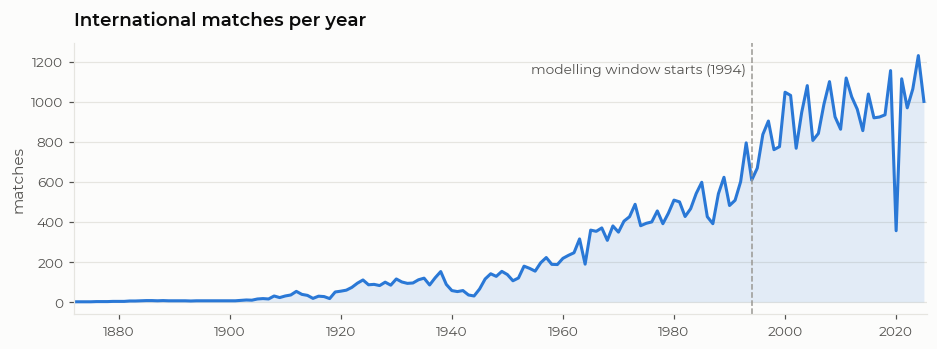

29,837 matches since 1994  |  mean goals per match since 1994: 2.77


In [5]:
per_year = matches[matches.date.dt.year < 2026].groupby(matches.date.dt.year).size()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(per_year.index, per_year.values, color=BLUE, alpha=.12, linewidth=0)
ax.plot(per_year.index, per_year.values, color=BLUE, lw=2)
ax.axvline(TRAIN_START.year, color=MUTED, lw=1, ls='--')
ax.text(TRAIN_START.year - 1, per_year.max() * .97, 'modelling window starts (1994)',
        ha='right', va='top', color=INK_2, fontsize=9)
ax.set(title='International matches per year', ylabel='matches', xlim=(1872, 2025.5))
ax.grid(axis='x', visible=False)
save(fig, '01_matches_per_year'); plt.show()

print(f'{(matches.date >= TRAIN_START).sum():,} matches since 1994  |  '
      f'mean goals per match since 1994: {(matches.home_score + matches.away_score)[matches.date >= TRAIN_START].mean():.2f}')

col_0,Home win,Draw,Away win
row_0,,,
Home team at home,50.9%,23.2%,25.9%
Neutral venue,42.6%,23.4%,34.0%


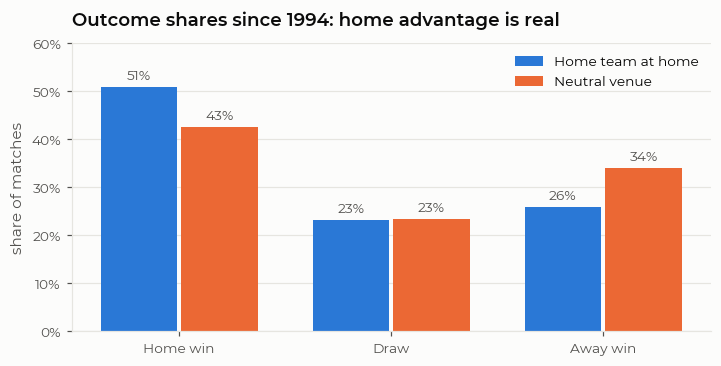

In [6]:
modern = matches[matches.date >= TRAIN_START]
result_label = np.select([modern.home_score > modern.away_score, modern.home_score == modern.away_score],
                         ['Home win', 'Draw'], 'Away win')
venue = np.where(modern.neutral, 'Neutral venue', 'Home team at home')
outcome_share = pd.crosstab(venue, result_label, normalize='index')[['Home win', 'Draw', 'Away win']]
display(outcome_share.style.format('{:.1%}'))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(3); w = .36
for k, (row, color) in enumerate([('Home team at home', BLUE), ('Neutral venue', ORANGE)]):
    vals = outcome_share.loc[row].values
    bars = ax.bar(x + (k - .5) * (w + .02), vals, w, color=color, label=row)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + .01, f'{v:.0%}', ha='center', va='bottom', fontsize=9, color=INK_2)
ax.set_xticks(x, outcome_share.columns)
ax.set(title='Outcome shares since 1994: home advantage is real', ylabel='share of matches', ylim=(0, .6))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.grid(axis='x', visible=False); ax.legend(loc='upper right')
save(fig, '02_outcome_by_venue'); plt.show()

**Takeaways.**
- The number of internationals has exploded since the 1990s (more federations, Nations Leagues, expanded qualifiers). Training on **1994 onwards** keeps the modern game (3 points per win, current confederation structure) while still giving ~30,000 matches.
- Home advantage is large: the home side wins about half of its home matches, but only ~45% at neutral venues, where the "home" label is just the first-listed team. This motivates an explicit `is_home` feature, and **symmetrising** predictions at neutral World Cup venues (section 9).
- Draws are about a quarter of all results. This is the hardest class to predict, which matters for model choice: we need **well-calibrated probabilities**, not just argmax accuracy.

## 3. Feature engineering

Every feature of a match is computed **only from matches strictly before it**, so there is no target leakage.

### 3.1 Elo rating with tuned parameters

World-Football-Elo style update after each match:

$$R'_{home} = R_{home} + K \cdot G \cdot (W - W_e), \qquad W_e = \frac{1}{1 + 10^{-(R_{home} - R_{away} + H)/400}}$$

* $K$ depends on the competition (World Cup 60, continental finals 50, qualifiers & Nations Leagues 40, other tournaments 30, friendlies 20), scaled by a tuned factor `k_scale`.
* $G$ grows with the goal difference (1, 1.5, then $(11+N)/8$).
* $H$ is the home-advantage bonus (0 at neutral venues), also tuned.

The two hyper-parameters are tuned by grid search, minimising the Brier score of $W_e$ **on training-period matches only (1994–2019)**.

In [7]:
MAJOR_FINALS = {'UEFA Euro', 'Copa América', 'African Cup of Nations', 'AFC Asian Cup', 'Gold Cup',
                'CONCACAF Championship', 'Oceania Nations Cup', 'Confederations Cup'}

def tournament_tier(name):
    if name == 'FIFA World Cup':
        return 'world_cup'
    if name in MAJOR_FINALS:
        return 'continental'
    if 'qualification' in name or 'Nations League' in name:
        return 'qualifier'
    return 'friendly' if name == 'Friendly' else 'other'

TIER_K = {'world_cup': 60, 'continental': 50, 'qualifier': 40, 'other': 30, 'friendly': 20}
matches['tier'] = matches.tournament.map(tournament_tier)
display(matches.tier.value_counts().to_frame('matches').T)

def run_elo(df, home_adv=100.0, k_scale=1.0, start=1500.0):
    """Sequential Elo. Returns pre-match ratings, expected home score and final ratings."""
    ratings = {}
    n = len(df)
    pre_home, pre_away, expected = np.empty(n), np.empty(n), np.empty(n)
    rows = zip(df.home_team.values, df.away_team.values, df.home_score.values,
               df.away_score.values, df.neutral.values, df.tier.values)
    for i, (h, a, hs, as_, neutral, tier) in enumerate(rows):
        rh, ra = ratings.get(h, start), ratings.get(a, start)
        pre_home[i], pre_away[i] = rh, ra
        we = 1.0 / (10 ** (-(rh - ra + (0.0 if neutral else home_adv)) / 400) + 1.0)
        expected[i] = we
        w = 1.0 if hs > as_ else 0.5 if hs == as_ else 0.0
        gd = abs(hs - as_)
        g = 1.0 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8
        delta = k_scale * TIER_K[tier] * g * (w - we)
        ratings[h], ratings[a] = rh + delta, ra - delta
    return pre_home, pre_away, expected, ratings

tier,friendly,qualifier,other,continental,world_cup
matches,18084,17020,9882,3391,964


In [8]:
actual = np.select([matches.home_score > matches.away_score, matches.home_score == matches.away_score], [1.0, 0.5], 0.0)
tune_mask = ((matches.date >= TRAIN_START) & (matches.date < VALID_START)).values

grid = []
for home_adv in [50, 75, 100, 125, 150]:
    for k_scale in [0.75, 1.0, 1.25, 1.5]:
        _, _, we, _ = run_elo(matches, home_adv, k_scale)
        grid.append({'home_adv': home_adv, 'k_scale': k_scale,
                     'brier': np.mean((actual[tune_mask] - we[tune_mask]) ** 2)})
elo_grid = pd.DataFrame(grid)
display(elo_grid.pivot(index='home_adv', columns='k_scale', values='brier')
        .style.format('{:.5f}').highlight_min(axis=None, props='font-weight:bold; background-color:#dbe8f8'))

ELO_PARAMS = elo_grid.loc[elo_grid.brier.idxmin(), ['home_adv', 'k_scale']].to_dict()
print('Selected Elo parameters:', ELO_PARAMS)

k_scale,0.750000,1.000000,1.250000,1.500000
home_adv,,,,
50,0.13835,0.13851,0.13920,0.14020
75,0.13638,0.13647,0.13711,0.13806
100,0.13554,0.13553,0.13608,0.13695
125,0.13575,0.13560,0.13604,0.13681
150,0.13690,0.13657,0.13687,0.13752


Selected Elo parameters: {'home_adv': 100.0, 'k_scale': 1.0}


In [9]:
matches['elo_home'], matches['elo_away'], matches['elo_expected'], final_ratings = run_elo(matches, **ELO_PARAMS)

active = set(matches.loc[matches.date >= '2024-01-01', 'home_team']) | set(matches.loc[matches.date >= '2024-01-01', 'away_team'])
elo_now = (pd.Series(final_ratings, name='elo').loc[sorted(active)]
           .sort_values(ascending=False).round(0).astype(int))
print('Elo top 15 on 1 June 2026 (teams active since 2024)')
display(elo_now.head(15).to_frame().T)

Elo top 15 on 1 June 2026 (teams active since 2024)


,Spain,Argentina,France,England,Brazil,Colombia,Portugal,Ecuador,Netherlands,Germany,Japan,Croatia,Morocco,Uruguay,Mexico
elo,2227,2188,2143,2085,2066,2057,2041,2025,2023,1997,1994,1989,1985,1977,1974


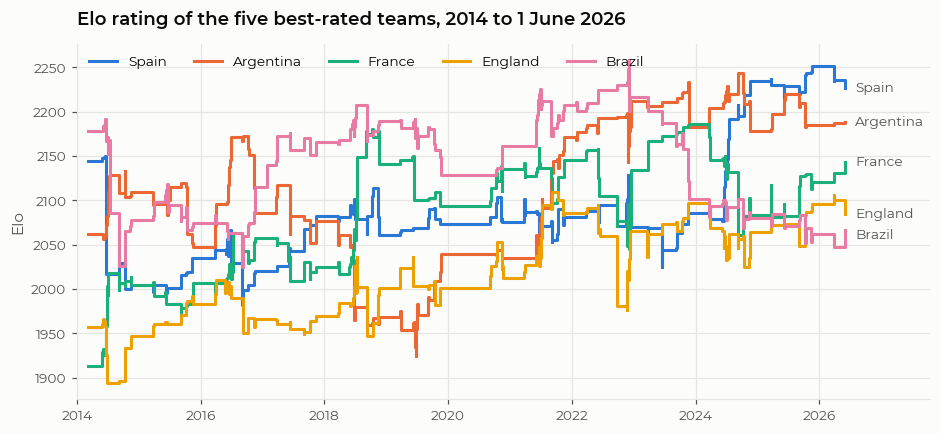

In [10]:
matches['match_id'] = matches.index

def team_view(df, side):
    other = 'away' if side == 'home' else 'home'
    return pd.DataFrame({'match_id': df.match_id, 'date': df.date, 'side': side,
                         'team': df[f'{side}_team'], 'opp': df[f'{other}_team'],
                         'gf': df[f'{side}_score'], 'ga': df[f'{other}_score'],
                         'elo': df[f'elo_{side}'], 'opp_elo': df[f'elo_{other}']})

long = (pd.concat([team_view(matches, 'home'), team_view(matches, 'away')])
        .sort_values(['date', 'match_id'], kind='stable').reset_index(drop=True))
long['pts'] = np.select([long.gf > long.ga, long.gf == long.ga], [3, 1], 0)

# Elo trajectories of the five highest-rated teams
top5 = elo_now.index[:5]
colors = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
fig, ax = plt.subplots(figsize=(10, 4.2))
ends = []
for team, c in zip(top5, colors):
    h = long[(long.team == team) & (long.date >= '2014-01-01')]
    xs = list(h.date) + [CUTOFF]; ys = list(h.elo) + [final_ratings[team]]
    ax.plot(xs, ys, color=c, lw=2, drawstyle='steps-post', label=team)
    ends.append([team, final_ratings[team]])
ends.sort(key=lambda e: -e[1])                      # spread overlapping end labels
for k in range(1, len(ends)):
    ends[k][1] = min(ends[k][1], ends[k - 1][1] - 24)
for team, y in ends:
    ax.text(CUTOFF + pd.Timedelta(days=60), y, team, va='center', fontsize=9, color=INK_2)
ax.set(title='Elo rating of the five best-rated teams, 2014 to 1 June 2026', ylabel='Elo')
ax.set_xlim(pd.Timestamp('2014-01-01'), CUTOFF + pd.Timedelta(days=500))
ax.legend(loc='upper left', ncol=5)
save(fig, '03_elo_top5'); plt.show()

### 3.2 Form, attack/defence, strength of schedule, momentum

Computed per team on a long (one row per team per match) table, always with `shift(1)` so the current match is excluded.

In [11]:
grp = long.groupby('team', sort=False)

def past_mean(col, window):
    return grp[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())

long['pts5']      = past_mean('pts', 5)          # points per game, last 5
long['pts10']     = past_mean('pts', 10)         # points per game, last 10
long['gf10']      = past_mean('gf', 10)          # goals scored per game, last 10
long['ga10']      = past_mean('ga', 10)          # goals conceded per game, last 10
long['opp_elo10'] = past_mean('opp_elo', 10)     # strength of schedule
long['elo_mom']   = long.elo - grp['elo'].shift(10)              # Elo change over last 10 games
long['rest']      = grp['date'].diff().dt.days.clip(upper=365)   # days since previous match
long['exp']       = np.log1p(grp.cumcount())                     # experience: log(# previous matches)

TEAM_FEATS = ['pts5', 'pts10', 'gf10', 'ga10', 'opp_elo10', 'elo_mom', 'rest', 'exp']
wide = long.pivot(index='match_id', columns='side', values=TEAM_FEATS)
wide.columns = [f'{f}_{side}' for f, side in wide.columns]
matches = matches.drop(columns=wide.columns, errors='ignore').join(wide, on='match_id')

### 3.3 Head-to-head record

In [12]:
def head_to_head(df):
    """Previous meetings and the home team's (Laplace-smoothed) score share in them."""
    record = {}
    n_prev, share = np.zeros(len(df)), np.full(len(df), 0.5)
    for i, (h, a, hs, as_) in enumerate(zip(df.home_team, df.away_team, df.home_score, df.away_score)):
        key = (h, a) if h < a else (a, h)
        n, s_first = record.get(key, (0, 0.0))
        s_home = s_first if h == key[0] else n - s_first
        n_prev[i], share[i] = n, (s_home + 1) / (n + 2)
        w = 1.0 if hs > as_ else 0.5 if hs == as_ else 0.0
        record[key] = (n + 1, s_first + (w if h == key[0] else 1 - w))
    return n_prev, share, record

n_prev, matches['h2h_share'], H2H = head_to_head(matches)
matches['h2h_n'] = np.log1p(n_prev)

### 3.4 Design matrix

The same `build_features` function is used for historical matches and, later, for World Cup fixtures, so training and prediction features are defined identically.

| Feature | Meaning |
|---|---|
| `elo_diff`, `elo_mean` | Elo gap (home − away) and average level of the two teams |
| `is_home` | 1 if the first-listed team plays at home, 0 at a neutral venue |
| `pts5_diff`, `pts10_diff` | difference in points per game over the last 5 / 10 matches |
| `gf10_*`, `ga10_*` (+ diffs) | goals scored / conceded per game over the last 10 matches |
| `opp_elo10_diff` | difference in average opponent Elo (strength of schedule) |
| `elo_mom_diff` | difference in Elo momentum (rating change over the last 10 matches) |
| `rest_diff` | difference in days since the previous match |
| `exp_diff` | difference in log number of previous internationals |
| `h2h_n`, `h2h_share` | number of past meetings and the home team's smoothed score share |
| `is_world_cup`, `is_continental`, `is_qualifier`, `is_friendly` | competition type |

**Target**: `0 = away win`, `1 = draw`, `2 = home win` (ordered, which the RPS metric below uses).

In [13]:
def build_features(df):
    X = pd.DataFrame(index=df.index)
    X['elo_diff'] = df.elo_home - df.elo_away
    X['elo_mean'] = (df.elo_home + df.elo_away) / 2
    X['is_home']  = df.is_home.astype(int)
    for f in TEAM_FEATS:
        X[f'{f}_diff'] = df[f'{f}_home'] - df[f'{f}_away']
    for f in ['gf10', 'ga10']:
        X[f'{f}_home'], X[f'{f}_away'] = df[f'{f}_home'], df[f'{f}_away']
    X['h2h_n'], X['h2h_share'] = df.h2h_n, df.h2h_share
    for t in ['world_cup', 'continental', 'qualifier', 'friendly']:
        X[f'is_{t}'] = (df.tier == t).astype(int)
    return X

matches['is_home'] = ~matches.neutral
matches['target'] = np.select([matches.home_score > matches.away_score,
                               matches.home_score == matches.away_score], [2, 1], 0)

model_df = matches[matches.date >= TRAIN_START].reset_index(drop=True)
X_all, y_all, dates = build_features(model_df), model_df.target.values, model_df.date
FEATURES = list(X_all.columns)
print(f'{len(FEATURES)} features, {len(X_all):,} matches')
display(X_all.describe().T[['mean', 'std', 'min', 'max']].round(2))
print('Missing values (first matches of new teams, imputed inside the pipelines):')
print(X_all.isna().sum()[X_all.isna().sum() > 0].to_dict())

21 features, 29,837 matches


,mean,std,min,max
elo_diff,17.75,247.28,-1210.69,1202.93
elo_mean,1588.87,206.28,861.57,2189.17
is_home,0.72,0.45,0.00,1.00
pts5_diff,0.04,0.95,-3.00,3.00
pts10_diff,0.04,0.76,-3.00,3.00
gf10_diff,0.04,0.86,-15.30,11.00
ga10_diff,-0.05,1.07,-17.30,18.93
opp_elo10_diff,6.62,129.73,-710.97,805.53
elo_mom_diff,0.73,71.07,-371.86,490.48
rest_diff,-1.63,70.38,-364.00,365.00


Missing values (first matches of new teams, imputed inside the pipelines):
{'pts5_diff': 86, 'pts10_diff': 86, 'gf10_diff': 86, 'ga10_diff': 86, 'opp_elo10_diff': 86, 'elo_mom_diff': 693, 'rest_diff': 86, 'gf10_home': 36, 'gf10_away': 54, 'ga10_home': 36, 'ga10_away': 54}
